# XRR analysis: LSMO / STO (001)

Steps in this notebook:
1. Read the CSV data
2. Plot the raw data
3. Transform the x and y axes (2θ → θ, q_z; counts → normalised log reflectivity)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WAVELENGTH = 1.540593  # Cu K-alpha1, in Angstrom
CSV_FILE = "XRR_LSMO_data.csv"

## 1. Read the data

In [2]:
df = pd.read_csv(CSV_FILE)
df.columns = ["two_theta", "intensity", "atten"]   # deg, counts, attenuation factor

print(df.shape)
df.head()

(691, 3)


,two_theta,intensity,atten
0,0.10,8.004127e+05,1.0
1,0.11,8.676281e+05,1.0
2,0.12,9.410931e+05,1.0
3,0.13,1.019310e+06,1.0
4,0.14,1.096101e+06,1.0


## 2. Plot the raw data

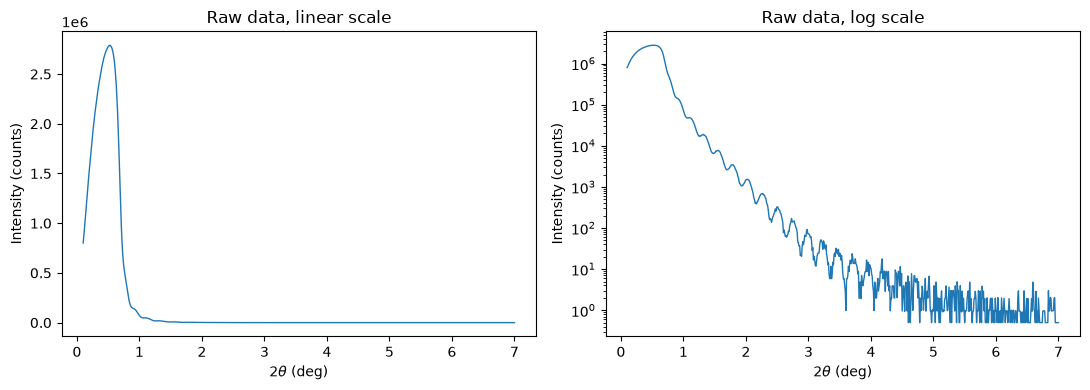

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(df["two_theta"], df["intensity"], lw=1)
axes[0].set_xlabel(r"2$\theta$ (deg)")
axes[0].set_ylabel("Intensity (counts)")
axes[0].set_title("Raw data, linear scale")

axes[1].semilogy(df["two_theta"], df["intensity"].clip(lower=0.5), lw=1)
axes[1].set_xlabel(r"2$\theta$ (deg)")
axes[1].set_ylabel("Intensity (counts)")
axes[1].set_title("Raw data, log scale")

plt.tight_layout()
plt.show()

## 3. Operations on the x and y axes

- x: θ = (2θ)/2 and the momentum transfer q_z = 4π sinθ / λ
- y: reflectivity normalised to the maximum, R = I / I_max, and log10(R)

Points with zero counts are dropped before taking the logarithm.

In [4]:
# x-axis transforms
df["theta"] = df["two_theta"] / 2.0
df["qz"] = 4 * np.pi * np.sin(np.radians(df["theta"])) / WAVELENGTH   # 1/Angstrom

# y-axis transforms
df["R"] = df["intensity"] / df["intensity"].max()

pos = df[df["R"] > 0].copy()          # drop zero-count points
pos["logR"] = np.log10(pos["R"])

pos[["two_theta", "theta", "qz", "R", "logR"]].head()

,two_theta,theta,qz,R,logR
0,0.10,0.050,0.007118,0.286858,-0.542333
1,0.11,0.055,0.007830,0.310947,-0.507314
2,0.12,0.060,0.008542,0.337276,-0.472015
3,0.13,0.065,0.009254,0.365308,-0.437341
4,0.14,0.070,0.009965,0.392829,-0.405797


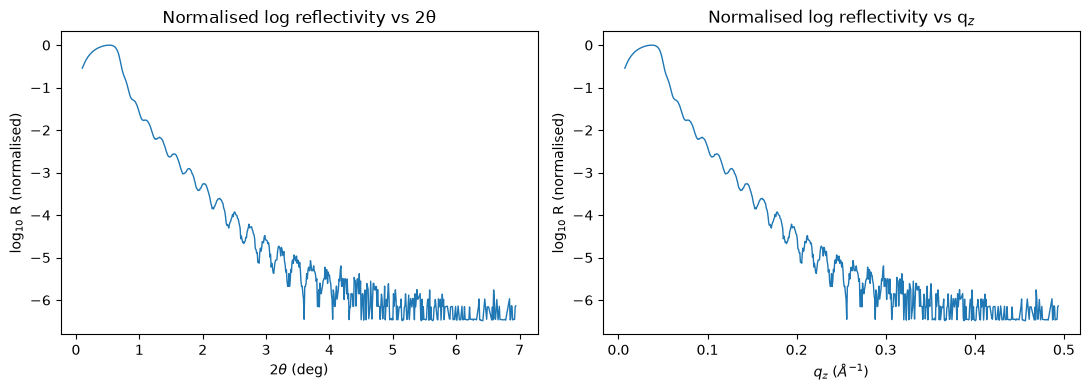

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(pos["two_theta"], pos["logR"], lw=1)
axes[0].set_xlabel(r"2$\theta$ (deg)")
axes[0].set_ylabel(r"log$_{10}$ R (normalised)")
axes[0].set_title("Normalised log reflectivity vs 2θ")

axes[1].plot(pos["qz"], pos["logR"], lw=1)
axes[1].set_xlabel(r"$q_z$ ($\AA^{-1}$)")
axes[1].set_ylabel(r"log$_{10}$ R (normalised)")
axes[1].set_title("Normalised log reflectivity vs q$_z$")

plt.tight_layout()
plt.show()